In [1]:
import sys
import os
from pathlib import Path

current_dir = Path(os.getcwd())
PROJECT_ROOT = current_dir.parent  
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocessing.pipeline import Pipeline
from src.utils.paths import TRAIN_DATA_PATH, TEST_DATA_PATH, DATA_DIR
from rdkit import Chem

import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Descriptors, MACCSkeys
import numpy as np

from rdkit.ML.Descriptors import MoleculeDescriptors

In [2]:
pipeline = Pipeline(download=False)

Extracting raw features:   0%|          | 0/2064 [00:00<?, ?it/s][13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
Extracting raw features:   0%|          | 8/2064 [00:00<00:26, 77.52it/s][13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: please use MorganGenerator
[13:52:13] DEPRECATION WARNING: plea

In [3]:
df = pipeline.get_raw_data()[0]

In [4]:
df

,Pubchem_ID,taste_cluster,SMILES
0,95609,0,CCC(C(=O)CC)O
1,104224,0,CCCCCCCCCCC(OC)OC
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO
3,10886,4,CCCCCC(=O)OCCCCC
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C
...,...,...,...
2059,229385,1,CCCCCCCCCCOC(=O)CC
2060,62387,2,CC1(C2CCC1([C@H](C2)OC=O)C)C
2061,8878,7,CCCCCCC(=O)OCC=C
2062,61262,1,CC(=O)OCC1=CCC2CC1C2(C)C


In [5]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
from tqdm import tqdm

# ====== 1. Функция Morgan FP — как в Extractor ======

def morgan_fp(smiles, bits=2048, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(bits, dtype=int)

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=bits
    )

    return np.array(fp, dtype=int)   


# ====== 2. Применяем ко всему DataFrame ======

def add_morgan_fingerprints(df, bits=2048, radius=2):
    fps = []

    for smi in tqdm(df["SMILES"], desc="Extracting Morgan fingerprints"):
        fps.append(morgan_fp(smi, bits=bits, radius=radius))

    fps = np.array(fps)
    fp_cols = [f"fp_{i}" for i in range(bits)]

    fp_df = pd.DataFrame(fps, columns=fp_cols)

    df_out = pd.concat([df.reset_index(drop=True), fp_df], axis=1)
    return df_out


# ====== 3. Пример использования ======

df_with_fp = add_morgan_fingerprints(df, bits=2048, radius=2)

df_with_fp.head()


Extracting Morgan fingerprints:   0%|          | 0/2064 [00:00<?, ?it/s][13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use MorganGenerator
[13:52:42] DEPRECATION WARNING: please use 

,Pubchem_ID,taste_cluster,SMILES,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,95609,0,CCC(C(=O)CC)O,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,104224,0,CCCCCCCCCCC(OC)OC,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,10886,4,CCCCCC(=O)OCCCCC,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
fp_cols = [col for col in df_with_fp.columns if col.startswith("fp_")]

zero_fp_cols = [col for col in fp_cols if (df_with_fp[col].sum() == 0)]

print(f"Найдено нулевых колонок: {len(zero_fp_cols)}")
zero_fp_cols[:20]  

Найдено нулевых колонок: 264


['fp_3',
 'fp_4',
 'fp_11',
 'fp_30',
 'fp_48',
 'fp_50',
 'fp_52',
 'fp_55',
 'fp_64',
 'fp_68',
 'fp_86',
 'fp_91',
 'fp_103',
 'fp_112',
 'fp_130',
 'fp_136',
 'fp_137',
 'fp_138',
 'fp_155',
 'fp_159']

In [7]:
df_cleaned_morgan = df_with_fp.drop(columns=zero_fp_cols)

In [8]:
df_cleaned_morgan

,Pubchem_ID,taste_cluster,SMILES,fp_0,fp_1,fp_2,fp_5,fp_6,fp_7,fp_8,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,95609,0,CCC(C(=O)CC)O,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,104224,0,CCCCCCCCCCC(OC)OC,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,10886,4,CCCCCC(=O)OCCCCC,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,229385,1,CCCCCCCCCCOC(=O)CC,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2060,62387,2,CC1(C2CCC1([C@H](C2)OC=O)C)C,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2061,8878,7,CCCCCCC(=O)OCC=C,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2062,61262,1,CC(=O)OCC1=CCC2CC1C2(C)C,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
df_test = pipeline.get_raw_data()[1]
df_test

,Pubchem_ID,SMILES
0,32594,CC(C)CC1=NC=CN=C1OC
1,7130,CC(C)CC1=NC2=CC=CC=C2C=C1
2,7455,CC1=CC=C(C=C1)C(=O)OC
3,31226,CC(=O)OCCCC1=CC=CC=C1
4,17000,CC1CCCC(C1=O)(C)C
...,...,...
883,26334,CCC1=NC=C(N=C1C)C
884,104421,CCOC1=NC(=CN=C1)C
885,21263168,CCCCCCCCCCCC(=O)OCCC(C)CCC=C(C)C
886,5368236,CCC/C=C/COC(=O)CC1=CC=CC=C1


---

In [10]:
import random
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

from tqdm import tqdm
from xgboost import XGBClassifier

In [11]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

----

## DFT (df_dft)

In [12]:
df_dft = pd.read_csv(Path(DATA_DIR) / 'pubchem_dft.csv')
df_dft

,Pubchem_ID,taste_cluster,SMILES,G,HOMO,LUMO,Gap,Dipole,E,CavityVolume,CavitySurface
0,95609,0,CCC(C(=O)CC)O,-27.094628,-10.8128,-6.9887,0.140533,3.869,-27.369769,122.600,191.80
1,104224,0,CCCCCCCCCCC(OC)OC,-50.265999,-10.9348,0.2265,0.410171,2.457,-50.795266,244.360,365.16
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO,-60.970606,-10.3723,-5.2295,0.188996,2.134,-61.746753,313.496,468.88
3,10886,4,CCCCCC(=O)OCCCCC,-42.945972,-11.4100,-6.4368,0.182764,3.073,-43.418595,207.360,323.24
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C,-42.076808,-10.3676,-7.6082,0.101403,4.148,-42.644300,204.552,288.12
...,...,...,...,...,...,...,...,...,...,...,...
2059,229385,1,CCCCCCCCCCOC(=O)CC,-49.270330,-11.0605,-6.3783,0.172070,3.180,-49.812813,238.664,349.16
2060,62387,2,CC1(C2CCC1([C@H](C2)OC=O)C)C,-40.916082,-11.0892,-6.7654,0.158897,3.773,-41.362330,181.808,251.12
2061,8878,7,CCCCCCC(=O)OCC=C,-38.719417,-11.2611,-6.4675,0.176160,2.859,-39.175686,184.464,285.00
2062,61262,1,CC(=O)OCC1=CCC2CC1C2(C)C,-43.019564,-10.3913,-6.3856,0.147207,2.705,-43.514330,195.840,279.60


---

## Morgan_fp (df_cleaned_morgan)

---

## RDKit (df_rdkit)

In [13]:
def extract_rdkit_descriptors(df):
    """
    Извлекает RDKit molecular descriptors для каждой молекулы
    """
    # Получаем список всех доступных дескрипторов
    descriptor_names = [desc[0] for desc in Descriptors._descList]
    calculator = MoleculeDescriptors.MolecularDescriptorCalculator(descriptor_names)
    
    descriptors_list = []
    valid_indices = []
    
    for idx, smi in enumerate(tqdm(df["SMILES"], desc="Extracting RDKit Descriptors")):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            try:
                # Вычисляем все дескрипторы
                descriptors = calculator.CalcDescriptors(mol)
                descriptors_list.append(descriptors)
                valid_indices.append(idx)
            except:
                # Если произошла ошибка при вычислении дескрипторов
                descriptors_list.append([np.nan] * len(descriptor_names))
                valid_indices.append(idx)
        else:
            # Если молекула невалидна
            descriptors_list.append([np.nan] * len(descriptor_names))
            valid_indices.append(idx)
    
    # Создаем DataFrame с дескрипторами
    descriptors_df = pd.DataFrame(descriptors_list, columns=descriptor_names)
    
    return descriptors_df

# Применяем функцию к вашему DataFrame
rdkit_descriptors = extract_rdkit_descriptors(df)
print(f"RDKit Descriptors shape: {rdkit_descriptors.shape}")

Extracting RDKit Descriptors: 100%|██████████| 2064/2064 [00:15<00:00, 133.76it/s]


RDKit Descriptors shape: (2064, 217)


In [14]:
df_rdkit = pd.concat([df, rdkit_descriptors], axis=1)
df_rdkit

,Pubchem_ID,taste_cluster,SMILES,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,95609,0,CCC(C(=O)CC)O,10.492824,10.492824,0.062500,-0.722222,0.590026,13.375000,116.160,...,0,0,0,0,0,0,0,0,0,0
1,104224,0,CCCCCCCCCCC(OC)OC,5.136898,5.136898,0.004714,0.004714,0.381623,11.200000,216.365,...,0,0,0,0,0,0,0,0,7,0
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO,8.660967,8.660967,0.362284,0.362284,0.284425,11.473684,268.485,...,0,0,0,0,0,0,0,0,12,0
3,10886,4,CCCCCC(=O)OCCCCC,11.058800,11.058800,0.023562,-0.023562,0.429221,10.000000,186.295,...,0,0,0,0,0,0,0,0,4,0
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C,11.903449,11.903449,0.101944,0.101944,0.484025,30.857143,192.302,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,229385,1,CCCCCCCCCCOC(=O)CC,10.796680,10.796680,0.071346,-0.071346,0.404385,10.266667,214.349,...,0,0,0,0,0,0,0,0,7,0
2060,62387,2,CC1(C2CCC1([C@H](C2)OC=O)C)C,10.368178,10.368178,0.165509,0.165509,0.612764,46.384615,182.263,...,0,0,0,0,0,0,0,0,0,0
2061,8878,7,CCCCCCC(=O)OCC=C,10.895092,10.895092,0.105553,-0.105553,0.333387,9.416667,170.252,...,0,0,0,0,0,0,0,0,3,0
2062,61262,1,CC(=O)OCC1=CCC2CC1C2(C)C,10.717786,10.717786,0.175784,-0.175784,0.498535,32.928571,194.274,...,0,0,0,0,0,0,0,0,0,0


In [15]:
zero_rdkit_cols = [col for col in df_rdkit.columns if (df_rdkit[col].sum() == 0)]

print(f"Найдено нулевых колонок: {len(zero_rdkit_cols)}")
zero_rdkit_cols[:20]  
df_rdkit = df_rdkit.drop(columns=zero_rdkit_cols)
df_rdkit

Найдено нулевых колонок: 46


,Pubchem_ID,taste_cluster,SMILES,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,fr_nitro,fr_oxazole,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_piperdine,fr_piperzine,fr_priamide,fr_pyridine,fr_unbrch_alkane
0,95609,0,CCC(C(=O)CC)O,10.492824,10.492824,0.062500,-0.722222,0.590026,13.375000,116.160,...,0,0,0,0,0,0,0,0,0,0
1,104224,0,CCCCCCCCCCC(OC)OC,5.136898,5.136898,0.004714,0.004714,0.381623,11.200000,216.365,...,0,0,0,0,0,0,0,0,0,7
2,5284499,6,CCCCCCCC/C=C\CCCCCCCCO,8.660967,8.660967,0.362284,0.362284,0.284425,11.473684,268.485,...,0,0,0,0,0,0,0,0,0,12
3,10886,4,CCCCCC(=O)OCCCCC,11.058800,11.058800,0.023562,-0.023562,0.429221,10.000000,186.295,...,0,0,0,0,0,0,0,0,0,4
4,12978217,3,C/C=C/C(=O)[C@@H]1[C@H](C=CCC1(C)C)C,11.903449,11.903449,0.101944,0.101944,0.484025,30.857143,192.302,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,229385,1,CCCCCCCCCCOC(=O)CC,10.796680,10.796680,0.071346,-0.071346,0.404385,10.266667,214.349,...,0,0,0,0,0,0,0,0,0,7
2060,62387,2,CC1(C2CCC1([C@H](C2)OC=O)C)C,10.368178,10.368178,0.165509,0.165509,0.612764,46.384615,182.263,...,0,0,0,0,0,0,0,0,0,0
2061,8878,7,CCCCCCC(=O)OCC=C,10.895092,10.895092,0.105553,-0.105553,0.333387,9.416667,170.252,...,0,0,0,0,0,0,0,0,0,3
2062,61262,1,CC(=O)OCC1=CCC2CC1C2(C)C,10.717786,10.717786,0.175784,-0.175784,0.498535,32.928571,194.274,...,0,0,0,0,0,0,0,0,0,0


---

## MACCS Keys (df_keys)

In [16]:
def extract_maccs_keys(df):
    """
    Извлекает MACCS Keys (166 бинарных признаков) для каждой молекулы
    """
    maccs_list = []
    
    for smi in tqdm(df["SMILES"], desc="Extracting MACCS Keys"):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            # Генерируем MACCS Keys
            fp = MACCSkeys.GenMACCSKeys(mol)
            # Преобразуем в массив numpy
            maccs_array = np.array(fp, dtype=int)
            maccs_list.append(maccs_array)
        else:
            # Если молекула невалидна, заполняем нулями
            maccs_list.append(np.zeros(167, dtype=int))
    
    # Создаем DataFrame с MACCS Keys
    maccs_df = pd.DataFrame(maccs_list)
    # Переименовываем колонки (MACCS Keys имеют 167 битов, но первый всегда 0)
    maccs_df.columns = [f'MACCS_{i}' for i in range(167)]
    # Удаляем первый столбец (MACCS_0), так как он всегда 0
    maccs_df = maccs_df.iloc[:, 1:]
    
    return maccs_df

# Применяем функцию к вашему DataFrame
maccs_keys = extract_maccs_keys(df)
print(f"MACCS Keys shape: {maccs_keys.shape}")

Extracting MACCS Keys: 100%|██████████| 2064/2064 [00:01<00:00, 1120.43it/s]


MACCS Keys shape: (2064, 166)


In [17]:
df_keys = pd.concat([df, maccs_keys], axis=1)
#df_keys

---

## Проверка Nan значений 

In [18]:
def check_nan_values(df, df_name="DataFrame"):
    """
    Проверяет наличие NaN значений в DataFrame и выводит подробную статистику
    """
    print(f"=== Анализ NaN значений в {df_name} ===")
    print(f"Общее количество NaN значений: {df.isna().sum().sum()}")
    print(f"Количество строк с хотя бы одним NaN: {df.isna().any(axis=1).sum()}")
    print(f"Количество столбцов с хотя бы одним NaN: {df.isna().any(axis=0).sum()}")
    print()
    
    # Детальная информация по столбцам с NaN
    nan_columns = df.columns[df.isna().any()].tolist()
    if nan_columns:
        print("Столбцы с NaN значениями:")
        for col in nan_columns:
            nan_count = df[col].isna().sum()
            nan_percent = (nan_count / len(df)) * 100
            print(f"  {col}: {nan_count} NaN ({nan_percent:.2f}%)")
    else:
        print("Нет столбцов с NaN значениями")
    
    return nan_columns

---

## Split

In [19]:
columns_to_drop = ['Pubchem_ID', 'taste_cluster', 'SMILES']
X = df_rdkit.drop(columns=columns_to_drop)
y = df_rdkit['taste_cluster']

In [20]:
nan_columns_X = check_nan_values(X, "Признаках (X)")

print(f"NaN в целевой переменной (y): {y.isna().sum()}")

=== Анализ NaN значений в Признаках (X) ===
Общее количество NaN значений: 0
Количество строк с хотя бы одним NaN: 0
Количество столбцов с хотя бы одним NaN: 0

Нет столбцов с NaN значениями
NaN в целевой переменной (y): 0


In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

---

In [199]:
columns_to_drop = ['Pubchem_ID', 'taste_cluster', 'SMILES']
X_rdkit = df_rdkit.drop(columns=columns_to_drop)
y = df_rdkit['taste_cluster']

X_train, X_val, y_train, y_val = train_test_split(
    X_rdkit, y, test_size=0.2, random_state=SEED, stratify=y
)

---

## Анализ корреляции признаков

In [186]:
import seaborn as sns

def analyze_correlations(X_train, X_val, correlation_threshold=0.93):
    """
    Анализирует корреляции между признаками и удаляет сильно коррелирующие.
    Работает только с DataFrame.
    """
    print("=== АНАЛИЗ КОРРЕЛЯЦИИ ПРИЗНАКОВ ===")
    
    if not isinstance(X_train, pd.DataFrame) or not isinstance(X_val, pd.DataFrame):
        raise ValueError("X_train и X_val должны быть pandas DataFrame с названиями колонок")
    
    # Вычисляем матрицу корреляций
    corr_matrix = X_train.corr()
    
    # Визуализация
    if X_train.shape[1] <= 50:
        plt.figure(figsize=(12, 10))
        sns.heatmap(corr_matrix, cmap='coolwarm', center=0, square=True, linewidths=0.5)
        plt.title('Матрица корреляций признаков')
        plt.tight_layout()
        plt.show()
    else:
        print(f"Признаков слишком много ({X_train.shape[1]}) для визуализации всей матрицы")
    
    # Поиск сильно коррелирующих пар
    high_corr_pairs = [(corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i,j])
                       for i in range(len(corr_matrix.columns))
                       for j in range(i+1, len(corr_matrix.columns))
                       if abs(corr_matrix.iloc[i,j]) > correlation_threshold]
    
    print(f"Найдено {len(high_corr_pairs)} пар признаков с корреляцией > {correlation_threshold}")
    
    # Удаляем один признак из пары с меньшей дисперсией
    columns_to_drop = set()
    for f1, f2, _ in high_corr_pairs:
        var1 = X_train[f1].var()
        var2 = X_train[f2].var()
        columns_to_drop.add(f2 if var1 >= var2 else f1)
    
    print(f"Будет удалено {len(columns_to_drop)} признаков из-за высокой корреляции")
    
    # Удаляем признаки
    X_train_reduced = X_train.drop(columns=columns_to_drop)
    X_val_reduced = X_val.drop(columns=columns_to_drop)
    
    print(f"Размерность после удаления коррелирующих признаков:")
    print(f"X_train: {X_train_reduced.shape}, X_val: {X_val_reduced.shape}")
    
    return X_train_reduced, X_val_reduced, list(columns_to_drop)

In [187]:
X_train_clean, X_val_clean, dropped_corr_features = analyze_correlations(X_train, X_val, correlation_threshold=0.93)

=== АНАЛИЗ КОРРЕЛЯЦИИ ПРИЗНАКОВ ===
Признаков слишком много (171) для визуализации всей матрицы
Найдено 129 пар признаков с корреляцией > 0.93
Будет удалено 45 признаков из-за высокой корреляции
Размерность после удаления коррелирующих признаков:
X_train: (1651, 126), X_val: (413, 126)


---

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled_rdkit = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X_train.columns, index=X_train.index)
X_val_scaled_rdkit = pd.DataFrame(scaler.transform(X_val),
                            columns=X_val.columns, index=X_val.index)

In [22]:
columns_to_drop_maccs = ['Pubchem_ID', 'taste_cluster', 'SMILES']
X_maccs = df_dft.drop(columns=columns_to_drop_maccs)

# Разделяем train / val по индексам (чтобы соответствовало RDKit разбиению)
X_maccs_train = X_maccs.loc[X_train.index]
X_maccs_val = X_maccs.loc[X_val.index]

print("MACCS keys:", X_maccs_train.shape)

# -------------------------
# Объединяем очищенные RDKit и MACCS
# -------------------------
X_train_rdmac = pd.concat([X_train, X_maccs_train], axis=1)
X_val_rdmac = pd.concat([X_val, X_maccs_val], axis=1)

MACCS keys: (1651, 8)


---

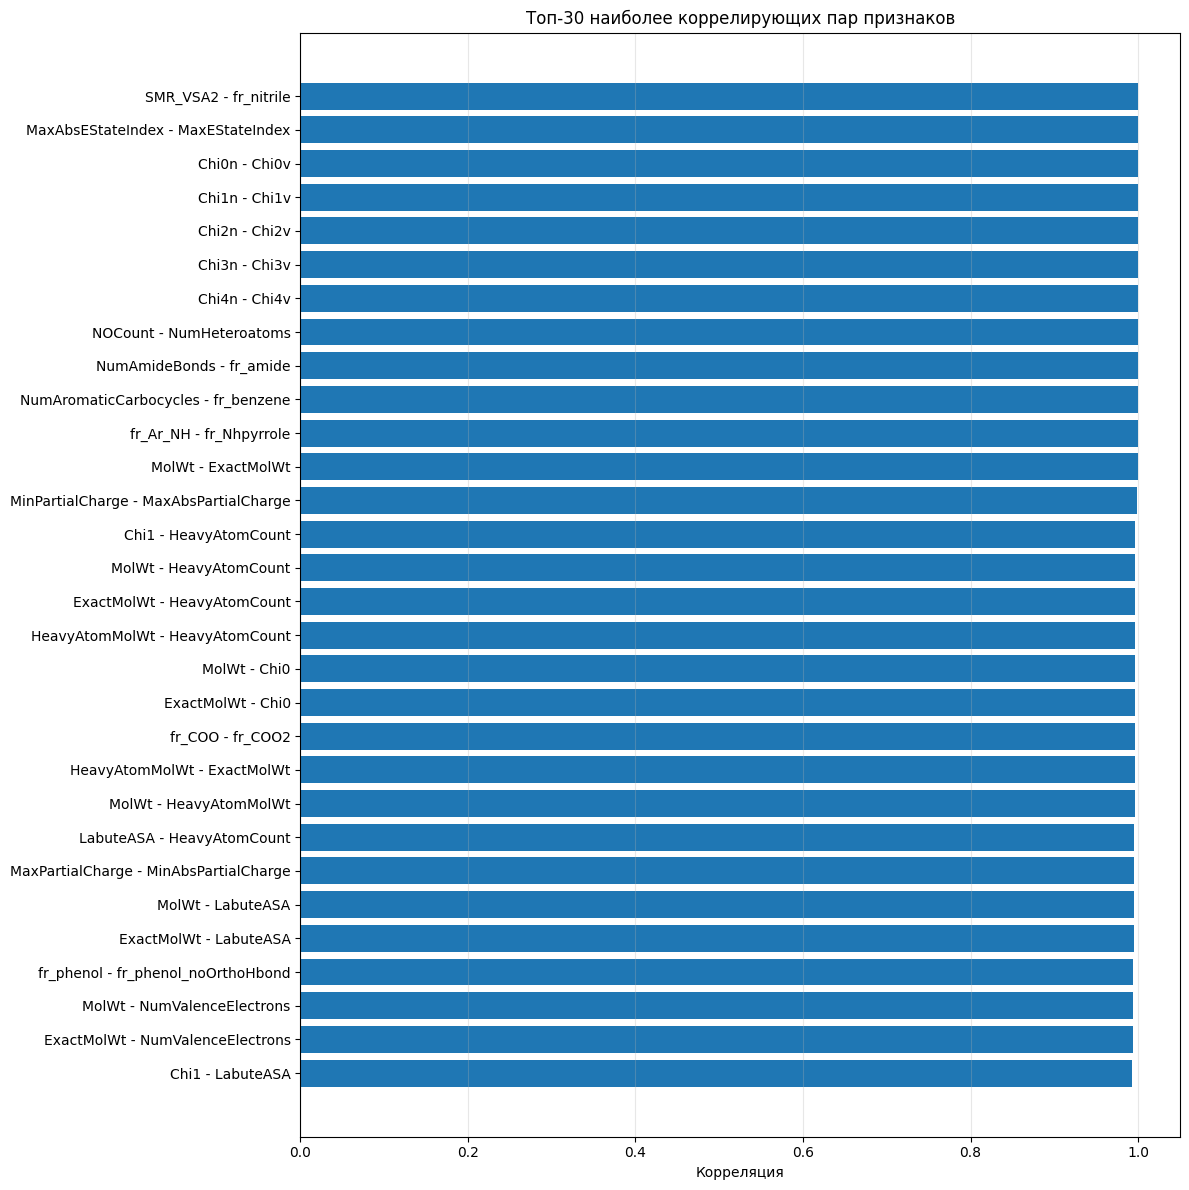

In [163]:
def plot_top_correlated_pairs(X_train, top_n=20, correlation_threshold=0.95):
    """
    Визуализирует топ-N наиболее коррелирующих пар признаков
    """
    corr_matrix = X_train.corr().abs()
    
    # Получаем верхний треугольник матрицы корреляций (без диагонали)
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Находим топ-N самых высоких корреляций
    high_corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_value = upper_triangle.iloc[i, j]
            if not np.isnan(corr_value) and corr_value > correlation_threshold:
                high_corr_pairs.append((
                    corr_matrix.columns[i],
                    corr_matrix.columns[j],
                    corr_value
                ))
    
    # Сортируем по убыванию корреляции
    high_corr_pairs = sorted(high_corr_pairs, key=lambda x: x[2], reverse=True)[:top_n]
    
    if not high_corr_pairs:
        print(f"Нет пар признаков с корреляцией > {correlation_threshold}")
        return
    
    # Создаем DataFrame для визуализации
    plot_data = pd.DataFrame(high_corr_pairs, columns=['Feature1', 'Feature2', 'Correlation'])
    
    # Визуализируем
    plt.figure(figsize=(12, max(6, len(high_corr_pairs) * 0.4)))
    y_pos = np.arange(len(high_corr_pairs))
    
    plt.barh(y_pos, plot_data['Correlation'])
    plt.yticks(y_pos, [f"{f1} - {f2}" for f1, f2, _ in high_corr_pairs])
    plt.xlabel('Корреляция')
    plt.title(f'Топ-{len(high_corr_pairs)} наиболее коррелирующих пар признаков')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return plot_data


top_corr_pairs = plot_top_correlated_pairs(X_train, top_n=30, correlation_threshold=0.95)

---

## PCA | LDA | t-SNE

нормализация

In [188]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled_rdkit = pd.DataFrame(scaler.fit_transform(X_train_clean),
                              columns=X_train_clean.columns, index=X_train_clean.index)
X_val_scaled_rdkit = pd.DataFrame(scaler.transform(X_val_clean),
                            columns=X_val_clean.columns, index=X_val_clean.index)

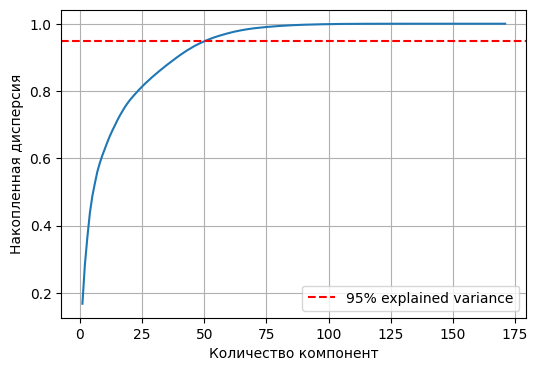

Выбранное число компонент PCA: 51


In [208]:
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled_rdkit)

explained_variance = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(6,4))
plt.plot(np.arange(1, len(explained_variance)+1), explained_variance)
plt.axhline(0.95, linestyle='--', color='red', label='95% explained variance')
plt.xlabel("Количество компонент")
plt.ylabel("Накопленная дисперсия")
plt.legend()
plt.grid(True)
plt.show()

# Выбираем число компонент, покрывающее ~95% дисперсии
n_components = int(np.argmax(explained_variance >= 0.95) + 1)
print("Выбранное число компонент PCA:", n_components)

pca = PCA(n_components=n_components)
X_train_pca_rdkit = pca.fit_transform(X_train_scaled_rdkit)
X_val_pca_rdkit = pca.transform(X_val_scaled_rdkit)

In [123]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

n_classes = len(np.unique(y_train))
lda_n_components = min(n_classes-1, X_train_scaled_rdkit.shape[1])

lda = LDA(n_components=lda_n_components)
X_train_lda = lda.fit_transform(X_train_scaled_rdkit, y_train)
X_val_lda = lda.transform(X_val_scaled_rdkit)

print("Форма X_train после LDA:", X_train_lda.shape)

Форма X_train после LDA: (1651, 7)


---

## Тренировка 

In [24]:
model = XGBClassifier(
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.7,
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist"
)

model.fit(X_train_rdmac, y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.7
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [25]:
y_pred = model.predict(X_val_rdmac)

f1_macro = f1_score(y_val, y_pred, average="macro")
print("F1-macro:", f1_macro)

print(classification_report(y_val, y_pred))

F1-macro: 0.43604284210069133
              precision    recall  f1-score   support

           0       0.53      0.65      0.58       106
           1       0.38      0.31      0.34        59
           2       0.57      0.45      0.51        44
           3       0.41      0.38      0.40        81
           4       0.52      0.54      0.53        57
           5       0.33      0.33      0.33         9
           6       0.38      0.53      0.44        17
           7       0.41      0.33      0.36        40

    accuracy                           0.47       413
   macro avg       0.44      0.44      0.44       413
weighted avg       0.47      0.47      0.46       413



In [ ]:
from catboost import CatBoostClassifier

if y_train.min() > 0:
    y_train = y_train - y_train.min()
    y_val = y_val - y_val.min()

model_cat = CatBoostClassifier(
    iterations=500,
    depth=7,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bylevel=0.7,
    loss_function='MultiClass',  
    eval_metric='MultiClass',    
    bootstrap_type='Bernoulli',
    verbose=5,  
    random_seed=42,
    thread_count=-1
)

model_cat.fit(
    X_train_rdmac, y_train,
    eval_set=(X_val_rdmac, y_val),
    early_stopping_rounds=50,
    plot=False)

0:	learn: 2.0416716	test: 2.0480352	best: 2.0480352 (0)	total: 246ms	remaining: 2m 2s
5:	learn: 1.8823544	test: 1.9101704	best: 1.9101704 (5)	total: 1.12s	remaining: 1m 32s
10:	learn: 1.7686872	test: 1.8143925	best: 1.8143925 (10)	total: 2.04s	remaining: 1m 30s
15:	learn: 1.6852859	test: 1.7498007	best: 1.7498007 (15)	total: 2.84s	remaining: 1m 25s
20:	learn: 1.6183775	test: 1.6972649	best: 1.6972649 (20)	total: 3.65s	remaining: 1m 23s
25:	learn: 1.5617421	test: 1.6564615	best: 1.6564615 (25)	total: 4.39s	remaining: 1m 20s
30:	learn: 1.5154744	test: 1.6269216	best: 1.6269216 (30)	total: 5.15s	remaining: 1m 17s
35:	learn: 1.4784240	test: 1.6042901	best: 1.6042901 (35)	total: 5.9s	remaining: 1m 16s
40:	learn: 1.4460339	test: 1.5846004	best: 1.5846004 (40)	total: 6.63s	remaining: 1m 14s
45:	learn: 1.4171221	test: 1.5669988	best: 1.5669988 (45)	total: 7.39s	remaining: 1m 12s
50:	learn: 1.3923022	test: 1.5519330	best: 1.5519330 (50)	total: 8.18s	remaining: 1m 12s
55:	learn: 1.3688574	test: 

In [29]:
y_pred = model_cat.predict(X_val_rdmac)

f1_macro = f1_score(y_val, y_pred, average="macro")
print("F1-macro:", f1_macro)

print(classification_report(y_val, y_pred))

F1-macro: 0.43032367549490785
              precision    recall  f1-score   support

           0       0.52      0.73      0.61       106
           1       0.39      0.24      0.29        59
           2       0.50      0.43      0.46        44
           3       0.39      0.38      0.39        81
           4       0.52      0.56      0.54        57
           5       0.50      0.33      0.40         9
           6       0.42      0.59      0.49        17
           7       0.36      0.20      0.26        40

    accuracy                           0.47       413
   macro avg       0.45      0.43      0.43       413
weighted avg       0.46      0.47      0.45       413



In [ ]:
df_test_fp = add_morgan_fingerprints(df_test, bits=2048, radius=2)

X_test = df_test_fp[[c for c in df_test_fp.columns if c.startswith("fp_")]].values

In [ ]:
test_preds = model.predict(X_test)
df_test_fp["pred_taste_cluster"] = test_preds

df_test_fp.head()

---

## SHAP 

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt

def perform_shap_analysis(model, X_val_sample, feature_names, y_sample=None):
    """
    Выполняет SHAP анализ для интерпретации модели.
    X_val_sample - DataFrame или numpy array
    y_sample - опционально, для проверки числа классов (не обязательно, так как теперь проверка по форме shap_values)
    """
    print("=== SHAP АНАЛИЗ ===")
    
    explainer = shap.Explainer(model)
    shap_values = explainer(X_val_sample)
    
    # Summary plot (beeswarm)
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_val_sample, feature_names=feature_names, show=False)
    plt.title('SHAP Summary Plot')
    plt.tight_layout()
    plt.show()
    
    # Bar plot (средняя важность)
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_val_sample, feature_names=feature_names, plot_type="bar", show=False)
    plt.title('SHAP Feature Importance (Bar Plot)')
    plt.tight_layout()
    plt.show()
    
    # Многоклассовая проверка на основе формы shap_values
    if shap_values.values.ndim == 3:
        print("Многоклассовая классификация - SHAP для каждого класса")
        n_classes = shap_values.values.shape[2]
        for i in range(n_classes):
            plt.figure(figsize=(10, 8))
            shap.summary_plot(shap_values[:, :, i], X_val_sample, feature_names=feature_names, show=False)
            plt.title(f'SHAP Summary Plot for Class {i}')
            plt.tight_layout()
            plt.show()
    
    return explainer, shap_values

=== SHAP АНАЛИЗ ===


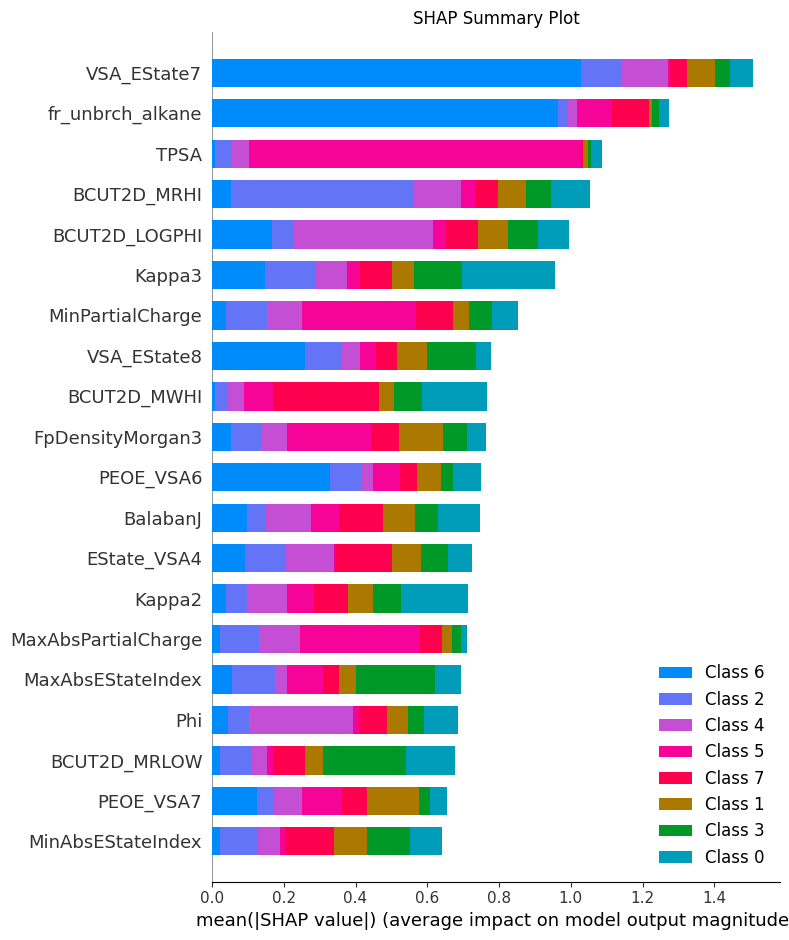

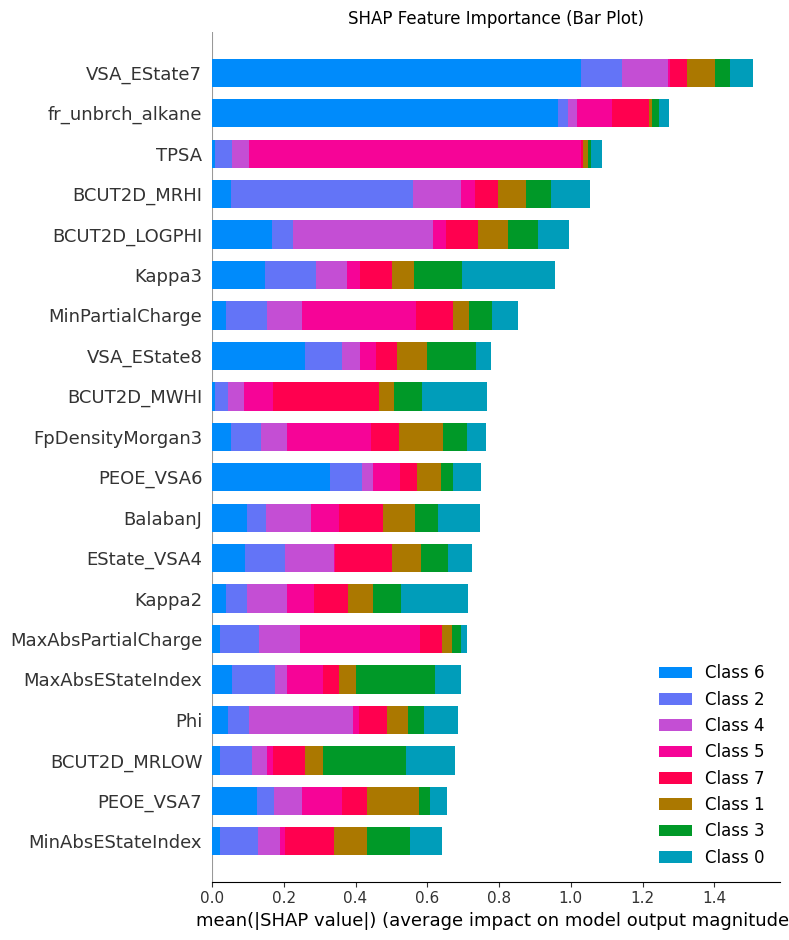

Многоклассовая классификация - SHAP для каждого класса


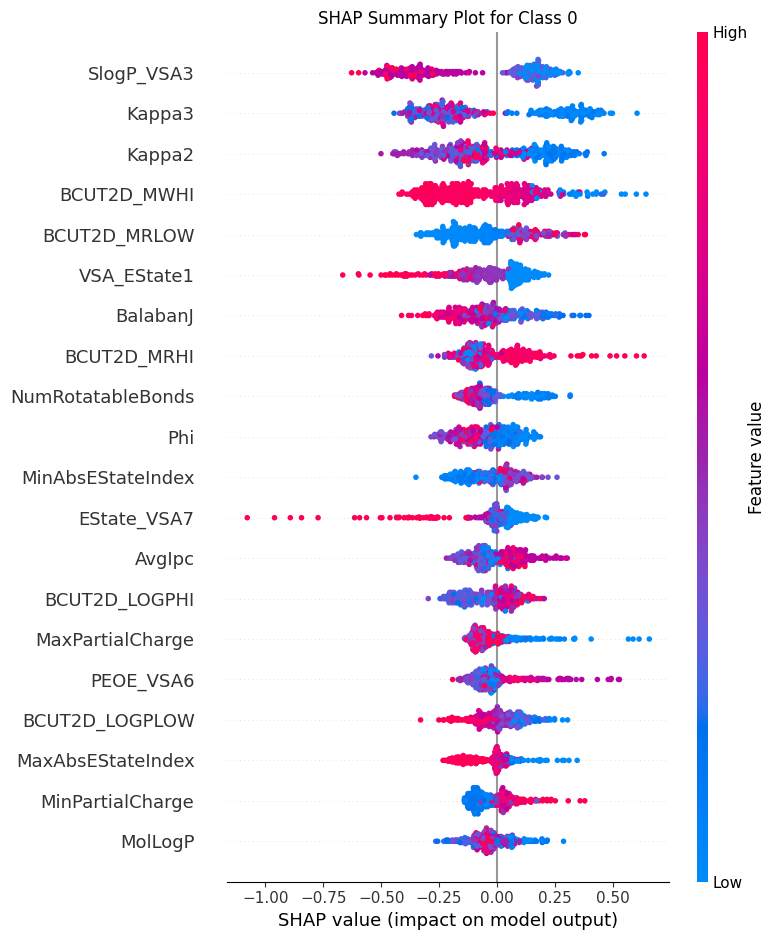

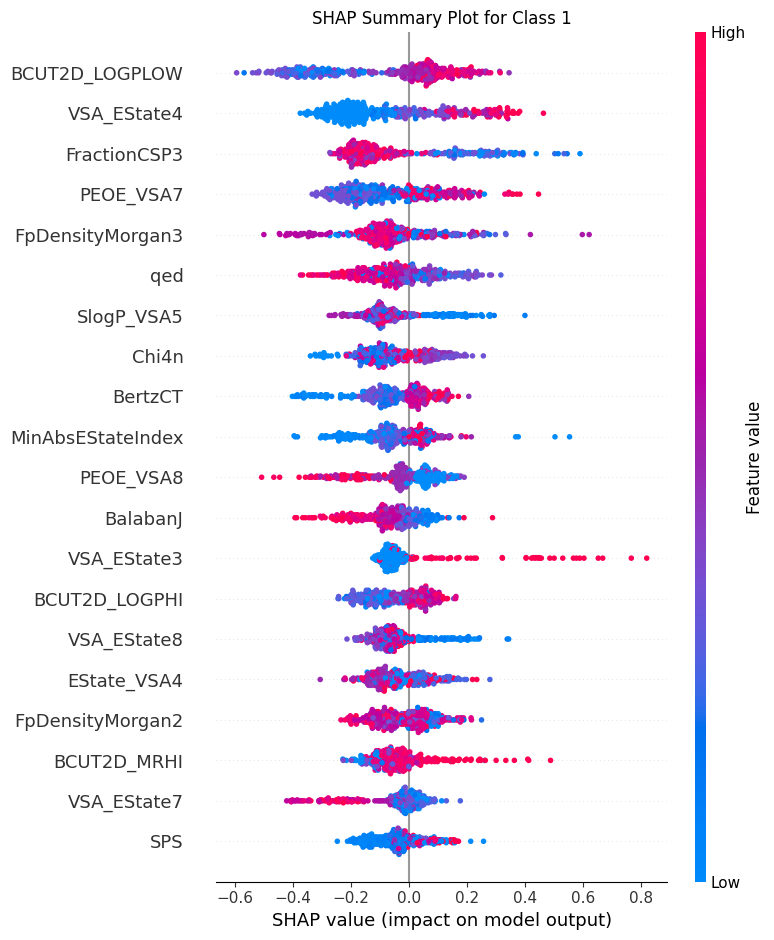

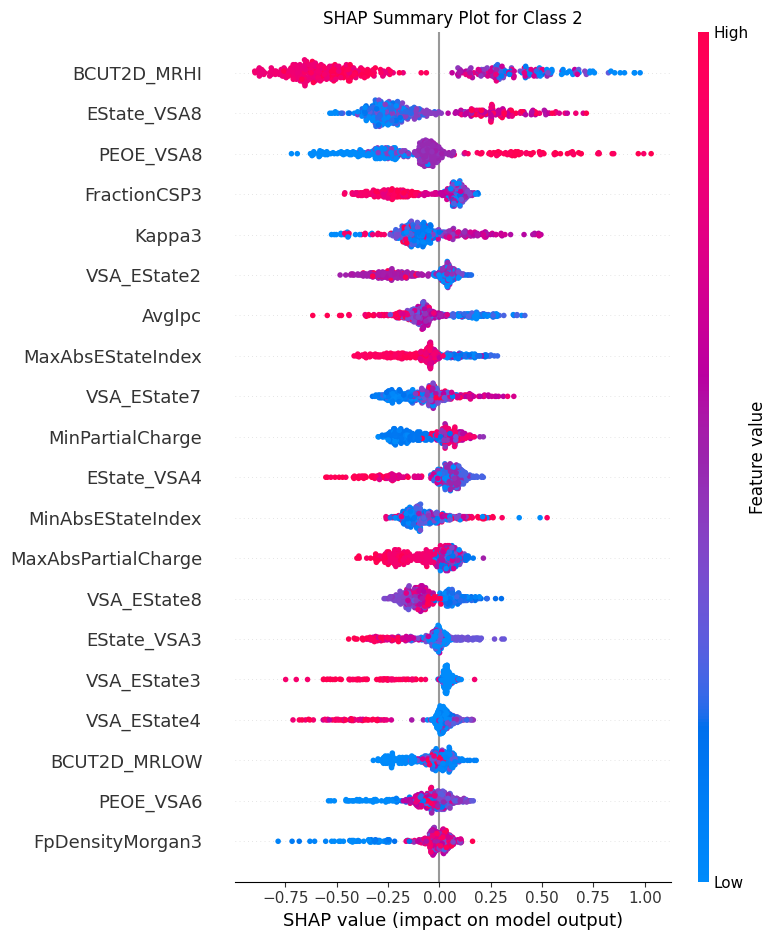

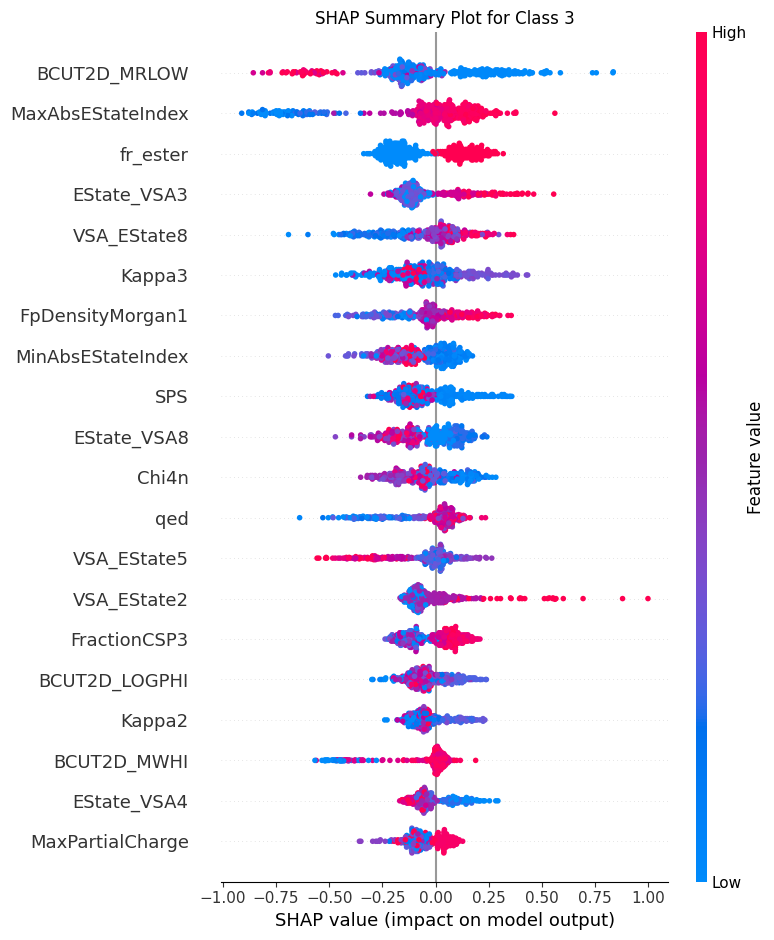

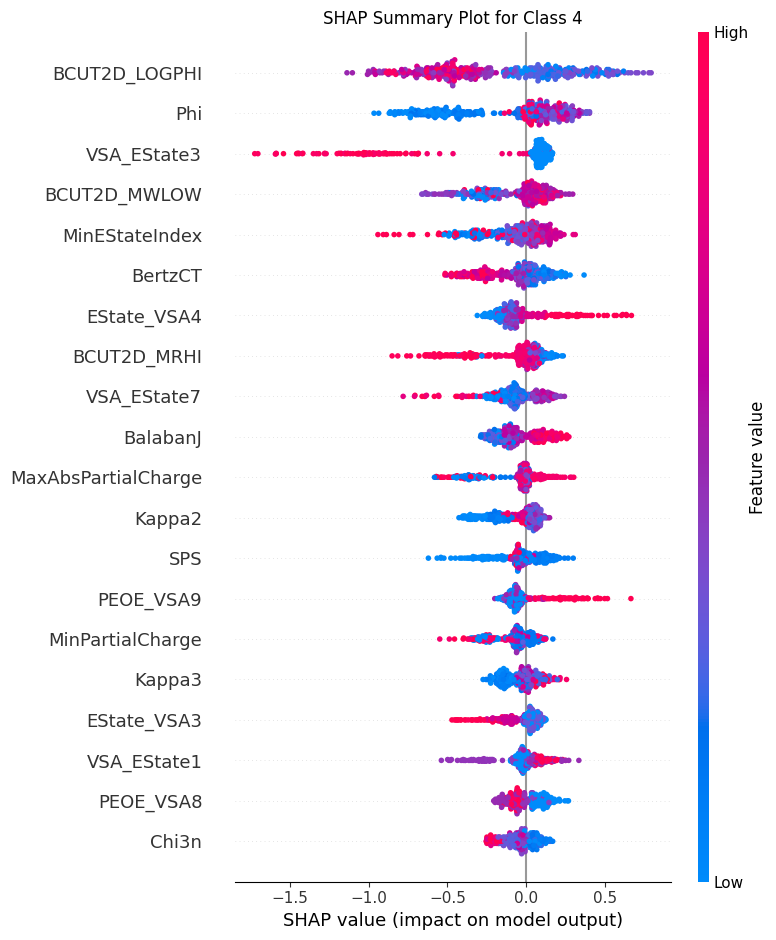

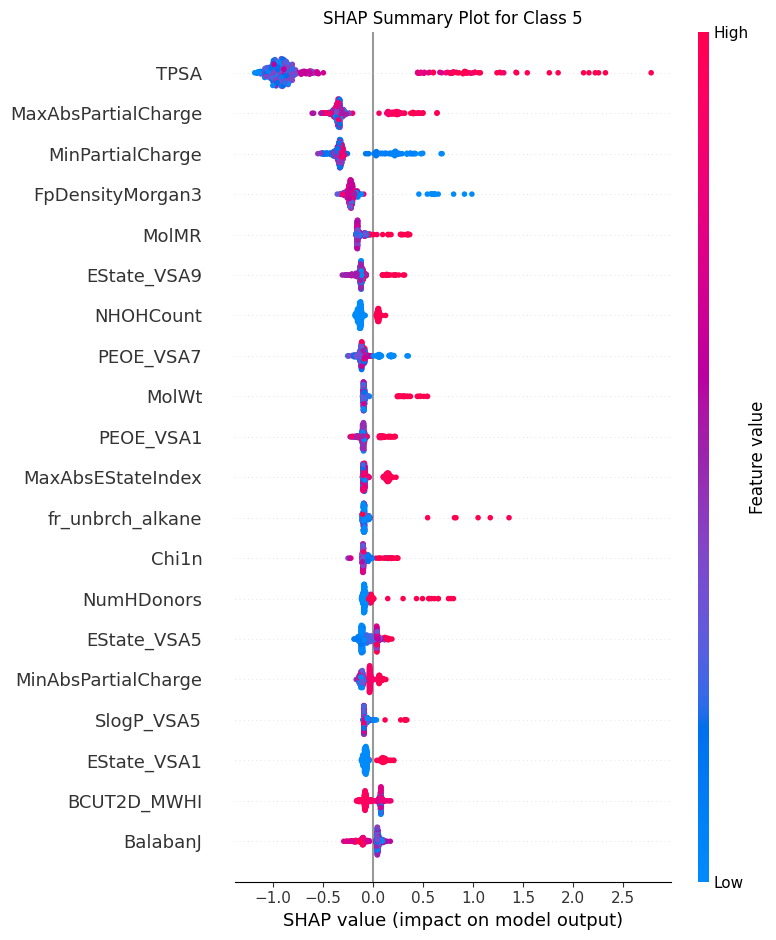

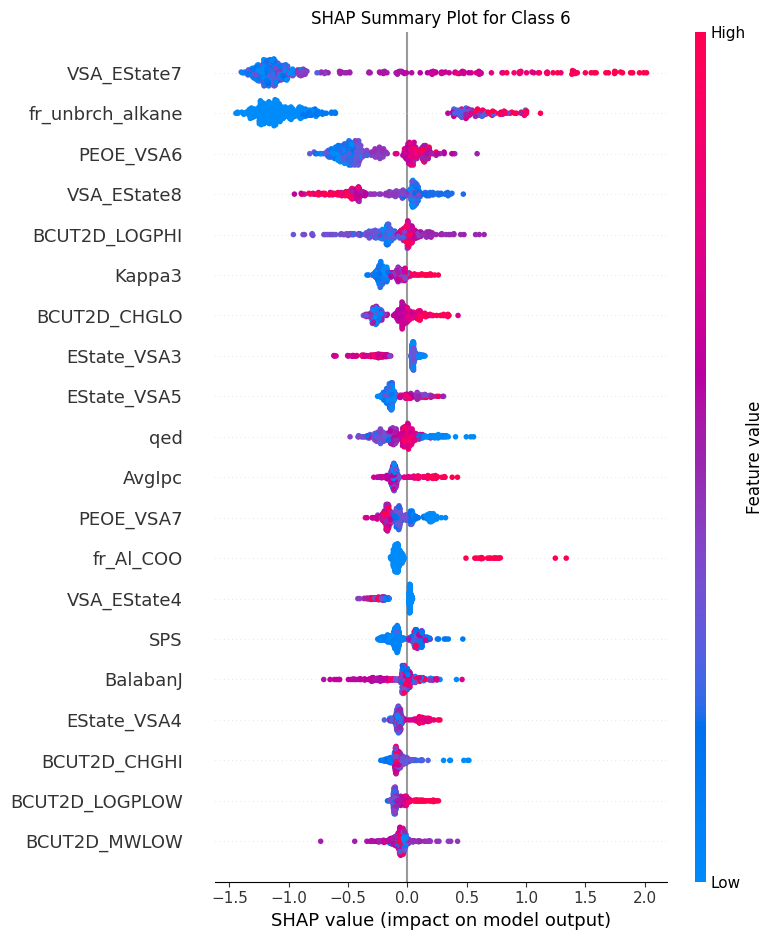

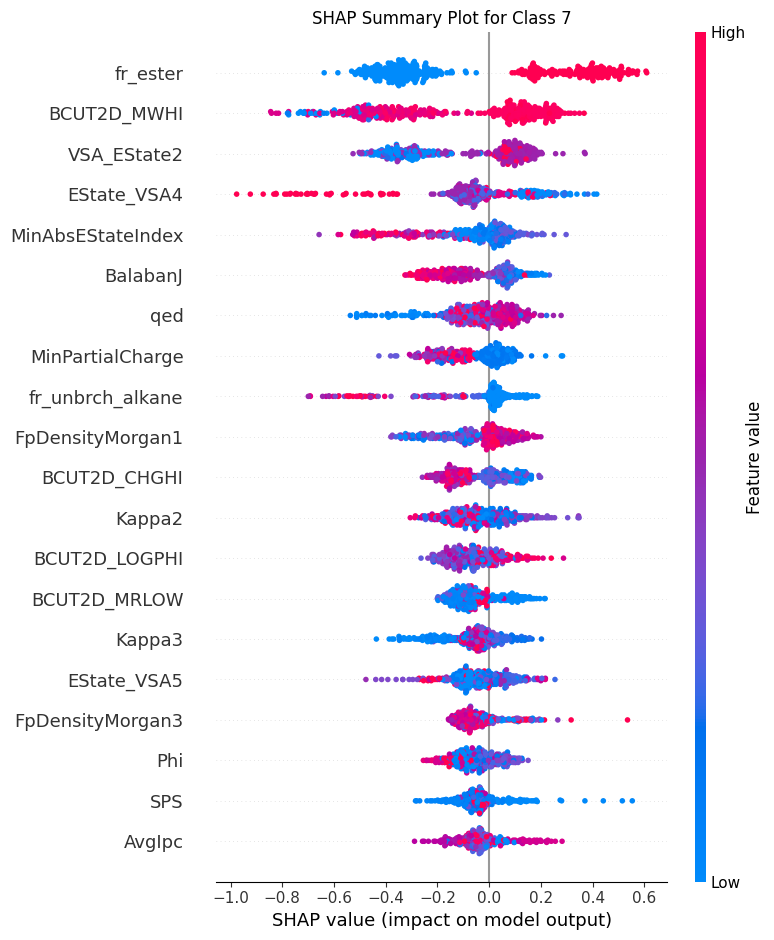

In [ ]:
sample_size = min(1000, X_val_scaled_rdkit.shape[0])


X_val_sample = X_val_scaled_rdkit.iloc[:sample_size]
explainer, shap_values = perform_shap_analysis(
    model, 
    X_val_sample, 
    feature_names=X_train_scaled_rdkit.columns, 
    y_sample=y_val[:sample_size]
)


In [180]:
# После perform_shap_analysis
# Получаем имена признаков
feature_names = np.array(X_train_scaled_rdkit.columns)

# Вычисляем среднюю абсолютную важность (mean abs SHAP)
# Для многоклассового: усредняем по сэмплам (axis=0) и классам (axis=2)
if shap_values.values.ndim == 3:
    mean_importance = np.mean(np.abs(shap_values.values), axis=(0, 2))
else:
    mean_importance = np.mean(np.abs(shap_values.values), axis=0)

# Устанавливаем threshold
# Вариант 1: Фиксированный (например, 0.01 - подберите под ваши данные, посмотрите на bar plot)
threshold = 0.0001

# Вариант 2: На основе percentile (оставить топ-50% признаков)
# threshold = np.percentile(mean_importance, 50)  # Оставит признаки выше медианы

# Вариант 3: На основе среднего
# threshold = np.mean(mean_importance)

print(f"Threshold для отбора: {threshold}")

# Отбираем признаки с важностью > threshold
selected_indices = np.where(mean_importance > threshold)[0]
selected_features = feature_names[selected_indices]

print(f"Отобрано {len(selected_features)} признаков из {len(feature_names)}")
print("Отобранные признаки:", selected_features)

# Создаём новые датасеты с отобранными признаками
X_train_selected = X_train_scaled_rdkit[selected_features]
X_val_selected = X_val_scaled_rdkit[selected_features]

# Опционально: переобучите модель на отобранных признаках и проверьте метрики
model_selected = XGBClassifier(
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.7,
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist"
)

model_selected.fit(X_train_selected, y_train)

y_pred_selected = model_selected.predict(X_val_selected)

f1_macro_selected = f1_score(y_val, y_pred_selected, average="macro")
print("F1-macro после отбора:", f1_macro_selected)

print(classification_report(y_val, y_pred_selected))

Threshold для отбора: 0.0001
Отобрано 150 признаков из 171
Отобранные признаки: ['MaxAbsEStateIndex' 'MaxEStateIndex' 'MinAbsEStateIndex' 'MinEStateIndex'
 'qed' 'SPS' 'MolWt' 'HeavyAtomMolWt' 'ExactMolWt' 'NumValenceElectrons'
 'MaxPartialCharge' 'MinPartialCharge' 'MaxAbsPartialCharge'
 'MinAbsPartialCharge' 'FpDensityMorgan1' 'FpDensityMorgan2'
 'FpDensityMorgan3' 'BCUT2D_MWHI' 'BCUT2D_MWLOW' 'BCUT2D_CHGHI'
 'BCUT2D_CHGLO' 'BCUT2D_LOGPHI' 'BCUT2D_LOGPLOW' 'BCUT2D_MRHI'
 'BCUT2D_MRLOW' 'AvgIpc' 'BalabanJ' 'BertzCT' 'Chi0' 'Chi0n' 'Chi0v'
 'Chi1' 'Chi1n' 'Chi1v' 'Chi2n' 'Chi2v' 'Chi3n' 'Chi3v' 'Chi4n' 'Chi4v'
 'HallKierAlpha' 'Ipc' 'Kappa1' 'Kappa2' 'Kappa3' 'LabuteASA' 'PEOE_VSA1'
 'PEOE_VSA10' 'PEOE_VSA11' 'PEOE_VSA12' 'PEOE_VSA13' 'PEOE_VSA14'
 'PEOE_VSA2' 'PEOE_VSA3' 'PEOE_VSA5' 'PEOE_VSA6' 'PEOE_VSA7' 'PEOE_VSA8'
 'PEOE_VSA9' 'SMR_VSA1' 'SMR_VSA10' 'SMR_VSA3' 'SMR_VSA4' 'SMR_VSA5'
 'SMR_VSA6' 'SMR_VSA7' 'SMR_VSA9' 'SlogP_VSA1' 'SlogP_VSA11' 'SlogP_VSA2'
 'SlogP_VSA3' 'SlogP_VSA4'

In [18]:
# -------------------------
# Установка необходимых пакетов (если не установлено)
# -------------------------
# !pip install lazypredict
# !pip install ipywidgets

# Для Jupyter Notebook: включение расширения (запустите один раз)
# !jupyter nbextension enable --py widgetsnbextension --sys-prefix

# После установки может потребоваться перезапуск kernel (Runtime > Restart runtime в Colab или аналогично в Jupyter)

from lazypredict.Supervised import LazyClassifier
from sklearn.metrics import f1_score
import pandas as pd

# -------------------------
# 1️⃣ Определяем кастомную метрику как функцию (не scorer)
# -------------------------
def f1_macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

# -------------------------
# 2️⃣ Инициализация LazyClassifier
# verbose=0 отключает лишний вывод
# predictions=False чтобы не хранить предсказания всех моделей
# custom_metric теперь функция
# -------------------------
clf = LazyClassifier(
    ignore_warnings=True,
    custom_metric=f1_macro,
    predictions=False,
    verbose=0
)

# -------------------------
# 3️⃣ Обучение и оценка моделей
# -------------------------
models, _ = clf.fit(
    X_train_scaled_rdkit, X_val_scaled_rdkit,
    y_train, y_val
)

# -------------------------
# 4️⃣ Сортировка моделей по f1_macro (имя колонки от __name__ функции)
# -------------------------
if 'f1_macro' in models.columns:
    models = models.sort_values('f1_macro', ascending=False)

# -------------------------
# 5️⃣ Вывод результатов
# -------------------------
pd.set_option('display.max_rows', None)
print(models)

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003341 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 15960
[LightGBM] [Info] Number of data points in the train set: 1651, number of used features: 149
[LightGBM] [Info] Start training from score -1.359403
[LightGBM] [Info] Start training from score -1.941076
[LightGBM] [Info] Start training from score -2.238652
[LightGBM] [Info] Start training from score -1.637695
[LightGBM] [Info] Start training from score -1.975414
[LightGBM] [Info] Start training from score -3.882776
[LightGBM] [Info] Start training from score -3.189629
[LightGBM] [Info] Start training from score -2.321540
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive 

In [19]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'objective': 'multi:softprob',
        'eval_metric': 'mlogloss',
        'tree_method': 'hist',
        'n_jobs': -1
    }
    model = XGBClassifier(**params)
    scores = cross_val_score(model, X_train_scaled_rdkit, y_train, cv=5, scoring='f1_macro')
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)  # 50-100 trials для хорошего поиска
best_params = study.best_params
print("Best params:", best_params)

# Затем обучите модель с best_params
model_opt = XGBClassifier(**best_params)
model_opt.fit(X_train_scaled_rdkit, y_train)
y_pred_opt = model_opt.predict(X_val_scaled_rdkit)
f1_opt = f1_score(y_val, y_pred_opt, average='macro')
print("F1-macro после Optuna:", f1_opt)

[I 2025-11-16 20:35:44,498] A new study created in memory with name: no-name-30992e2f-9c49-4c83-b9bc-8f2969e10ac8
[I 2025-11-16 20:36:18,285] Trial 0 finished with value: 0.4427697398837795 and parameters: {'n_estimators': 273, 'max_depth': 8, 'learning_rate': 0.2475015370854784, 'subsample': 0.6086153997190269, 'colsample_bytree': 0.6099365528878593}. Best is trial 0 with value: 0.4427697398837795.
[I 2025-11-16 20:36:48,183] Trial 1 finished with value: 0.4426475793245059 and parameters: {'n_estimators': 284, 'max_depth': 5, 'learning_rate': 0.20789458728132806, 'subsample': 0.8235925196363392, 'colsample_bytree': 0.5305618108154668}. Best is trial 0 with value: 0.4427697398837795.
[I 2025-11-16 20:38:22,031] Trial 2 finished with value: 0.44788741331474025 and parameters: {'n_estimators': 532, 'max_depth': 10, 'learning_rate': 0.06717723978176622, 'subsample': 0.8432581164740213, 'colsample_bytree': 0.6750745218737348}. Best is trial 2 with value: 0.44788741331474025.
[I 2025-11-16 

Best params: {'n_estimators': 184, 'max_depth': 7, 'learning_rate': 0.0476109776724495, 'subsample': 0.870566661269549, 'colsample_bytree': 0.7052007526121055}
F1-macro после Optuna: 0.4380743396230273


---

## Ансамбль моделей

In [63]:
import numpy as np

# y_train, y_val — Series (N,)
# создаём бинарные матрицы (N, 8)
y_train_bin = np.zeros((len(y_train), 8), dtype=int)
y_val_bin = np.zeros((len(y_val), 8), dtype=int)

for i in range(8):
    y_train_bin[:, i] = (y_train.values == i).astype(int)
    y_val_bin[:, i]  = (y_val.values == i).astype(int)


In [64]:
from xgboost import XGBClassifier

def make_binary_model():
    return XGBClassifier(
        n_estimators=500,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.7,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist"
    )

binary_models = []

for i in range(8):
    print(f"Training model {i+1}/8...")
    model = make_binary_model()
    model.fit(X_train, y_train_bin[:, i])
    binary_models.append(model)


Training model 1/8...
Training model 2/8...
Training model 3/8...
Training model 4/8...
Training model 5/8...
Training model 6/8...
Training model 7/8...
Training model 8/8...


In [65]:
val_probas = np.zeros((X_val.shape[0], 8))

for i, model in enumerate(binary_models):
    val_probas[:, i] = model.predict_proba(X_val)[:, 1]

In [67]:
# Assuming your earlier code for creating y_train_bin, y_val_bin, training binary_models, and generating val_probas is unchanged.

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

# Split val into meta_train and meta_test (e.g., 50% for meta training, 50% for evaluation)
val_probas_meta_train, val_probas_meta_test, y_meta_train, y_meta_test = train_test_split(
    val_probas, y_val, test_size=0.5, random_state=42, stratify=y_val
)

# Define and train the meta-model on meta_train only
meta_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.7,
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist"
)

meta_model.fit(val_probas_meta_train, y_meta_train)  # Train on meta_train subset

# Predict on meta_test (unseen by meta-model)
final_meta_test_pred = meta_model.predict(val_probas_meta_test)

# Compute unbiased F1 on meta_test
f1_macro = f1_score(y_meta_test, final_meta_test_pred, average='macro')
print("Unbiased F1-macro (8 smell clusters):", f1_macro)

Unbiased F1-macro (8 smell clusters): 0.29378152041195515
